In [24]:
import sys

sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tqdm

from src.config import load_config
from src.data import load_complete
from src.data.preprocessing import preprocess_from_config
from src.figures import plot_archetypes_loadings_grid

sns.set_style("whitegrid")
config = load_config()

In [25]:
SEED = config["unmixing"].getint("seed")  # pipeline (VCA/MVSA init) seed
PERM_SEED = 1000  # separate stream for the precinct shuffles
P = config["unmixing"].getint("n_archetypes") or None
PS = [
    2,
    3,
    4,
    5,
    6,
]  # sweep; anchors: config value (6) and nb08's min-pairwise-distance choice (4)
n_trials = 50

df = load_complete(config)

# Canonical preprocessing: reference precinct order shared by all runs
pre_ref = preprocess_from_config(df, config)
Y_ref = pre_ref.Y
L, N = Y_ref.shape
candidate_labels = pre_ref.candidate_labels
ref_ids = pd.Index(pre_ref.params["precinct_ids"])

candidates: 66 -> 66 (25th pct >= 1.0)
precincts:  92,488 -> 92,487 (total votes >= 1.0)
Y: 66 candidates x 92,487 precincts (valid_ballots normalization)


In [26]:
Y_ref.shape

(66, 92487)

/opt/homebrew/Caskroom/miniforge/base/envs/voting_unmixing_ph_env/lib/python3.13/site-packages/sklearn/decomposition/_nmf.py:1576: UserWarning: The multiplicative update ('mu') solver cannot update zeros present in the initialization, and so leads to poorer results when used jointly with init='nndsvd'. You may try init='nndsvda' or init='nndsvdar' instead.
  warnings.warn(


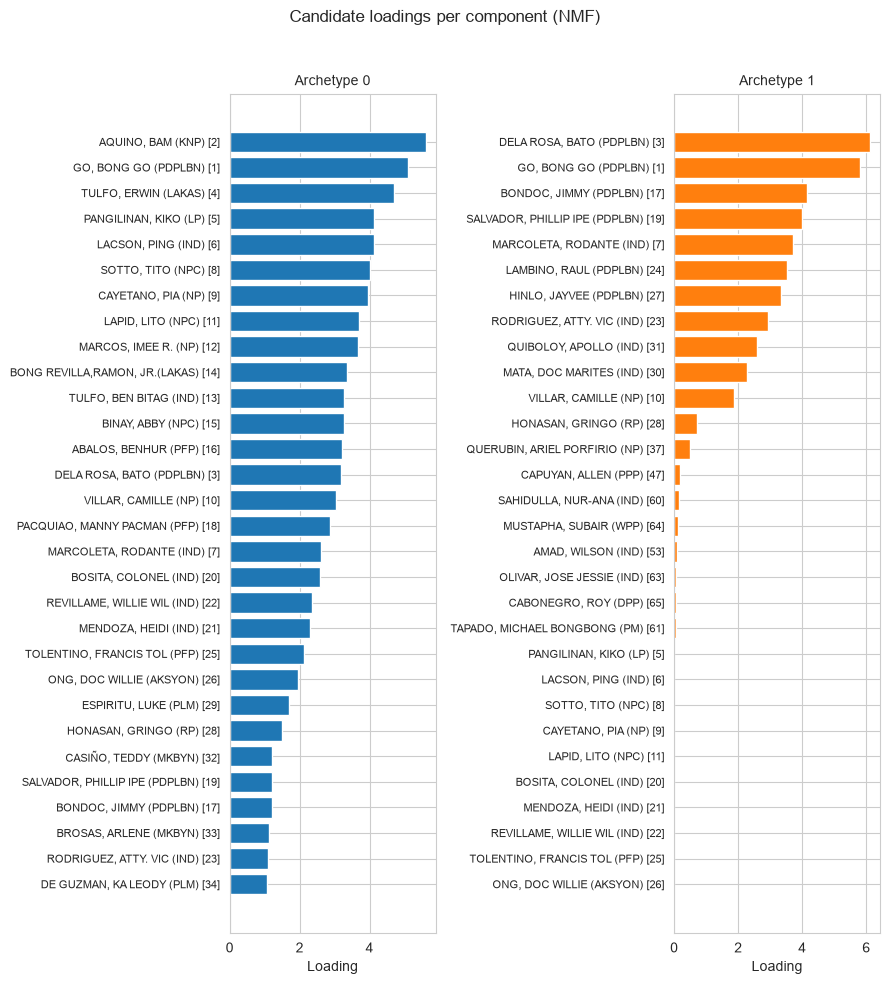

/opt/homebrew/Caskroom/miniforge/base/envs/voting_unmixing_ph_env/lib/python3.13/site-packages/sklearn/decomposition/_nmf.py:1576: UserWarning: The multiplicative update ('mu') solver cannot update zeros present in the initialization, and so leads to poorer results when used jointly with init='nndsvd'. You may try init='nndsvda' or init='nndsvdar' instead.
  warnings.warn(


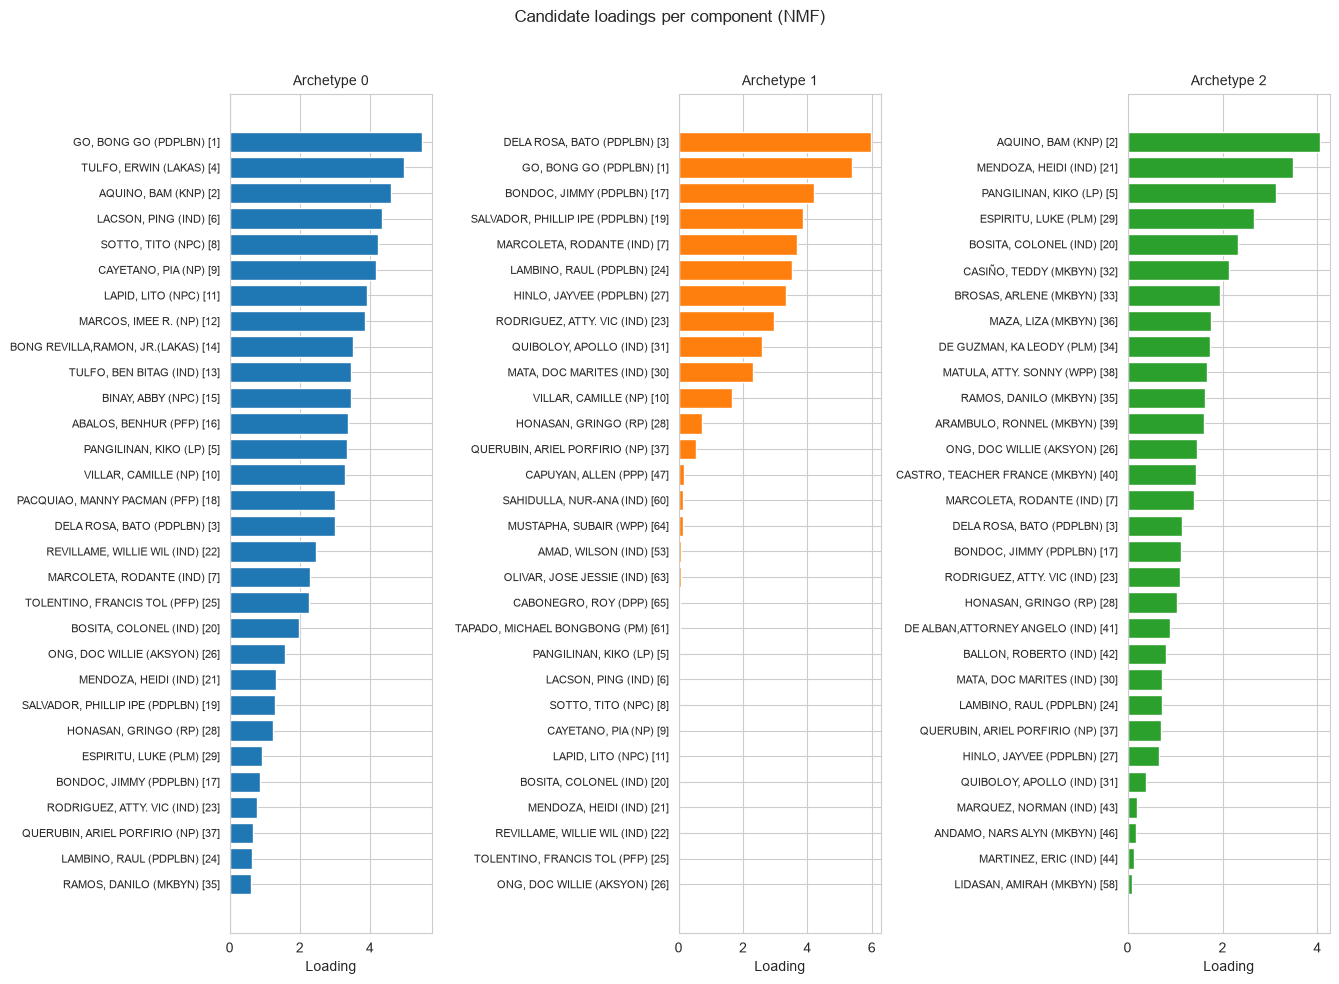

/opt/homebrew/Caskroom/miniforge/base/envs/voting_unmixing_ph_env/lib/python3.13/site-packages/sklearn/decomposition/_nmf.py:1576: UserWarning: The multiplicative update ('mu') solver cannot update zeros present in the initialization, and so leads to poorer results when used jointly with init='nndsvd'. You may try init='nndsvda' or init='nndsvdar' instead.
  warnings.warn(


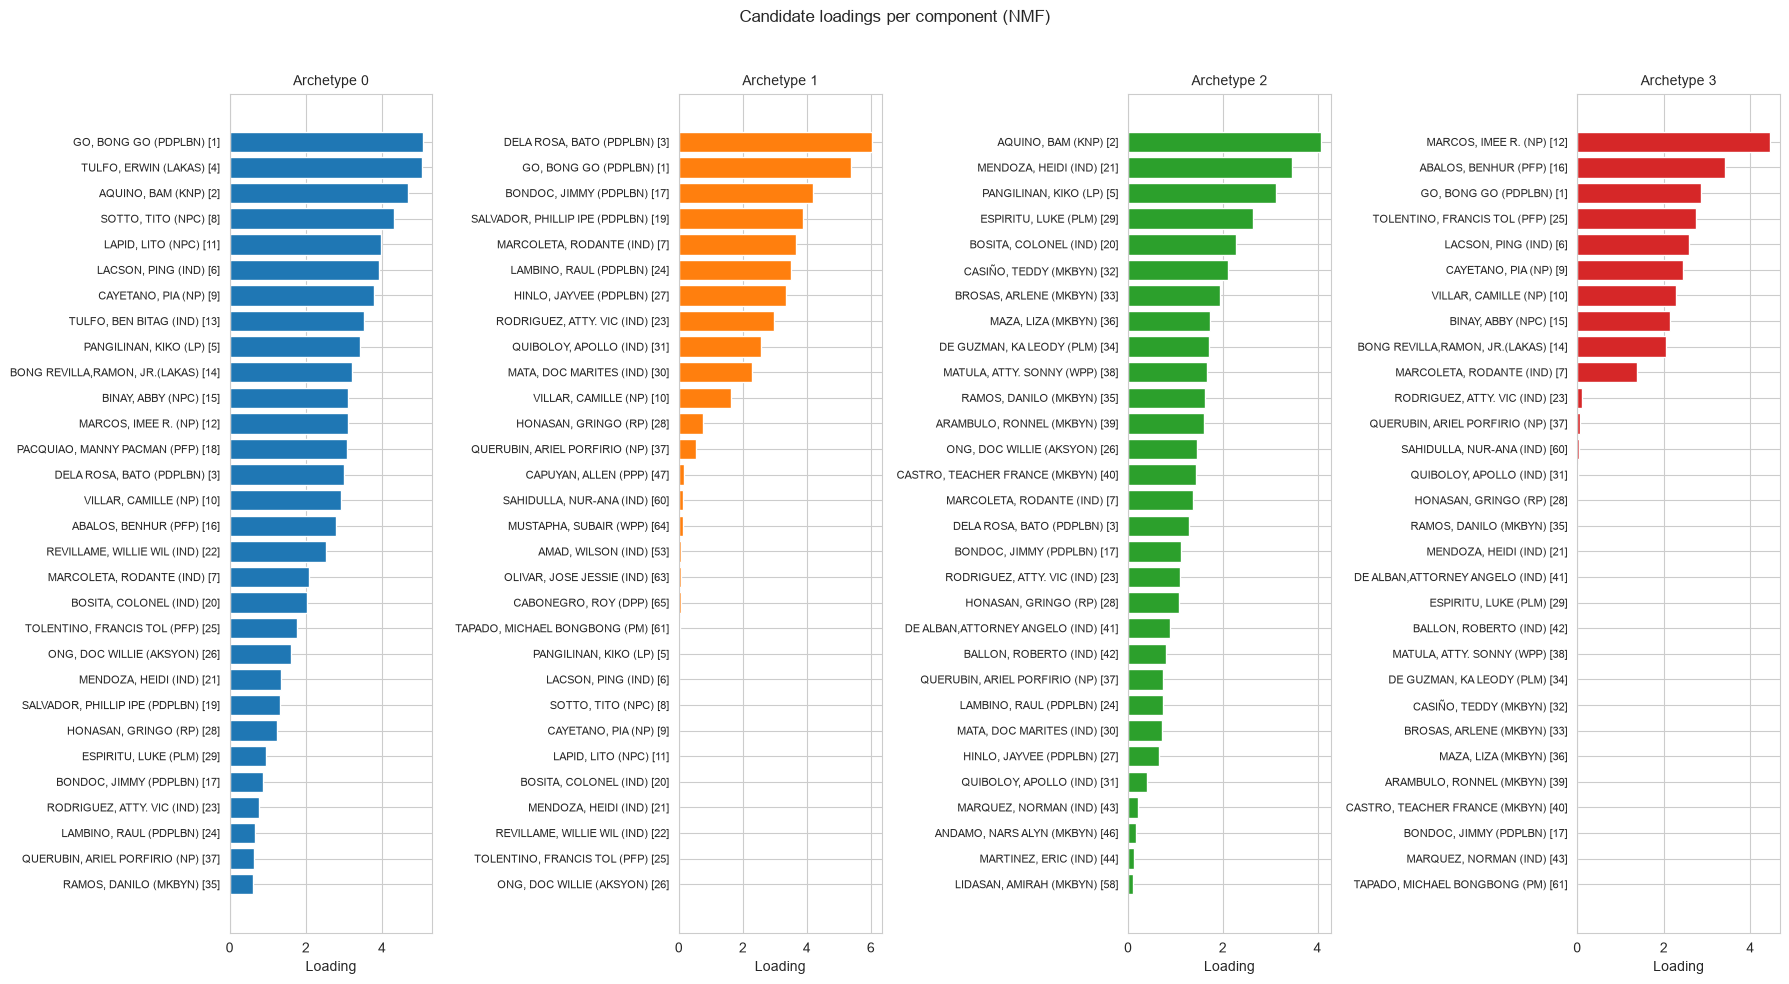

/opt/homebrew/Caskroom/miniforge/base/envs/voting_unmixing_ph_env/lib/python3.13/site-packages/sklearn/decomposition/_nmf.py:1576: UserWarning: The multiplicative update ('mu') solver cannot update zeros present in the initialization, and so leads to poorer results when used jointly with init='nndsvd'. You may try init='nndsvda' or init='nndsvdar' instead.
  warnings.warn(


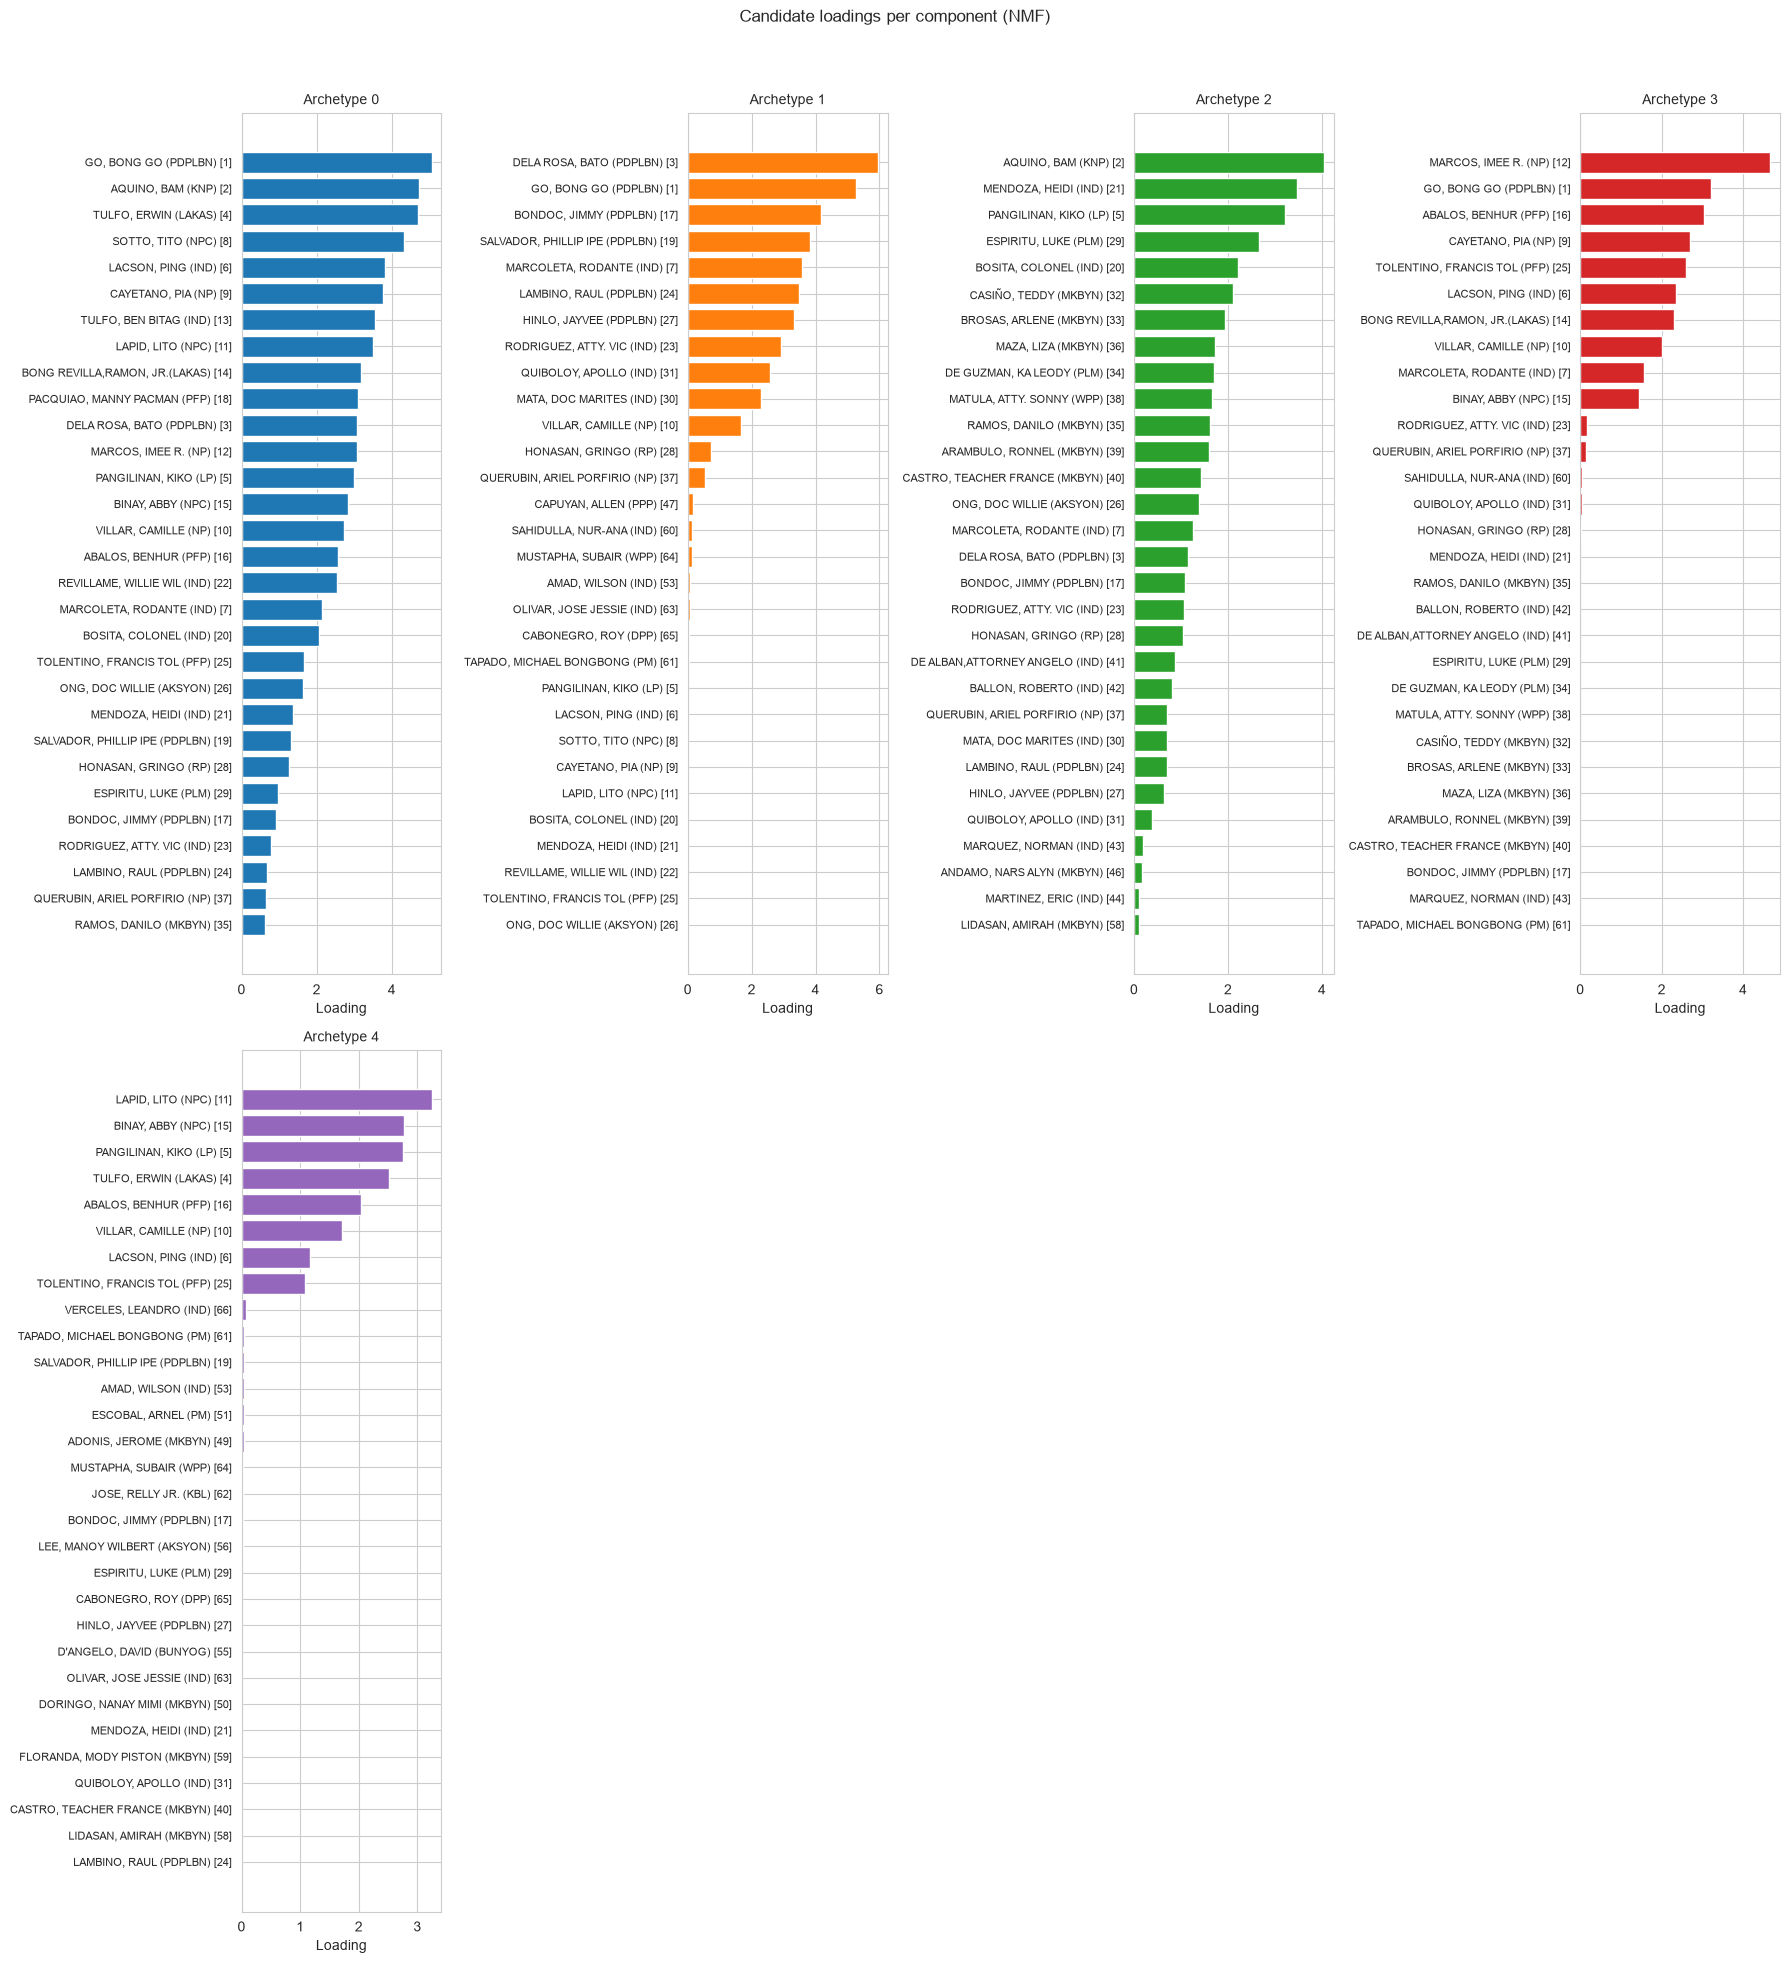

In [32]:
from sklearn.decomposition import NMF

for i in range(2, 6):
    model = NMF(n_components=i, init='nndsvd', beta_loss='kullback-leibler', solver='mu', max_iter=10000)
    W = model.fit_transform(Y_ref)

    plot_archetypes_loadings_grid(
        W, candidate_labels, top_n=30, suptitle="Candidate loadings per component (NMF)"
    )